<div style="font-family: 'Times New Roman', serif;">

**[Standard Exponential Distribution]**
1) probability density function:
$$f_X(x) = e^{-x} \mathbf{1}_{(0, \infty)}(x)$$

2) cumulative distribution function:
$$F_X(x) = \mathbb{P}(X \le x) = (1 - e^{-x}) \mathbf{1}_{(0, \infty)}(x)$$
$\to$ *Given that independent random events occur at a rate $\lambda = 1$ ($\frac{1}{\lambda}$: waiting time),  
$F_X(x)$ is the probability that the next event occurs within a duration of $x$*
</div>

In [26]:
import numpy as np
import matplotlib.pyplot as plt

In [27]:
x_plot = np.linspace(0, 6, 10000)
true_cdf = 1 - np.exp(-x_plot)

<div style="font-family: 'Times New Roman', serif;">

### Empirical CDF

$$\hat{F}_n(x) = \frac{1}{n} \sum_{i=1}^n \mathbf{1}(X_i \le x)$$

Let $X_{(1)} \leq X_{(2)} \leq ... \leq X_{(n)}$  
- $x < X_{(1)}$: $\hat{F}_n(x)=\frac{0}{n}$
- $X_{(1)} \leq x < X_{(2)}$: $\hat{F}_n(x)=\frac{1}{n}$  
...
- $X_{(k)} \leq x < X_{(k+1)}$: $\hat{F}_n(x)=\frac{k}{n}$  
...
- $X_{(n)} \leq x$: $\hat{F}_n(x)=\frac{n}{n}$  

</br>

Let $X_i \overset{i.i.d.}\sim  \text{Exp}(1) \quad \forall i \in {1, ..., n}$  

</div>

In [28]:
# drawing random sample data from exponential distribution
n = 800
samples  = np.random.exponential(scale=1.0, size = n) # scale = 1/lambda

# order statistics
sorted_samples = np.sort(samples)

# y values of ECDF
ecdf = np.arange(1, n+1)/n


<div style="font-family: 'Times New Roman', serif;">

**[Confidence interval of ECDF]**

By CLT, 
$$\frac{\hat{F}_n(x) - \mathbb{E}[\hat{F}_n(x)]}{\sqrt{\mathbb{V}[\hat{F}_n(x)]}}
=\sqrt{n}\frac{\hat{F}_n(x) - F_X(x)}{\sqrt{F_X(x)(1 - F_X(x))}} 
\xrightarrow{\mathcal{D}} \mathcal{N}(0, 1) \quad (n \to \infty)$$

Since $\hat{F}_n(x) \xrightarrow{\mathbb{P}} F(x)$,
$$\sqrt{\frac{\hat{F}_n(x)(1 - \hat{F}_n(x))}{F_X(x)(1 - F_X(x))}} \xrightarrow{\mathbb{P}} 1$$

by Slutsky's thm we have:
$$\sqrt{n}\frac{\hat{F}_n(x) - F_X(x)}{\sqrt{\hat{F}_n(x)(1 - \hat{F}_n(x))}} \xrightarrow{\mathcal{D}} \mathcal{N}(0, 1)$$

Therefore 

$$\mathbb{P}\left( -1.96 \le \sqrt{n}\frac{\hat{F}_n(x) - F_X(x)}{\sqrt{\hat{F}_n(x)(1 - \hat{F}_n(x))}} \le 1.96 \right) \to 0.95$$

The asymptotic 95% confidence interval is then constructed as:
$$\mathrm{CI}_{0.95}(x) = \left[ \hat{F}_n(x) - 1.96 \sqrt{\frac{\hat{F}_n(x)(1 - \hat{F}_n(x))}{n}}, \;\; \hat{F}_n(x) + 1.96 \sqrt{\frac{\hat{F}_n(x)(1 - \hat{F}_n(x))}{n}} \right]$$
</div>

In [29]:
se = np.sqrt(ecdf*(1-ecdf)/n)
CI_lower = np.clip(ecdf - 1.96*se, 0,1) #set CI bound to 0-1 using np.clip
CI_upper = np.clip(ecdf + 1.96*se, 0,1)

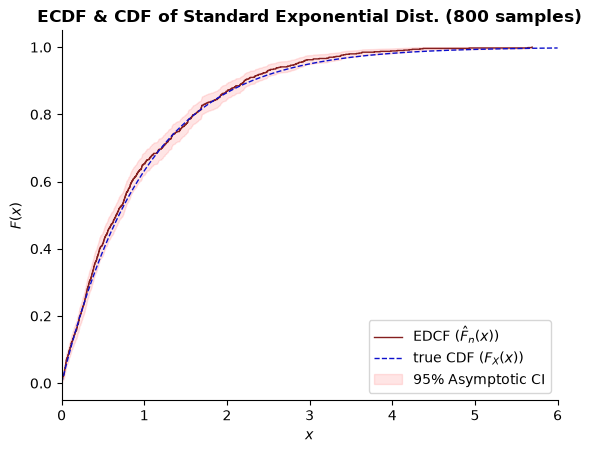

In [30]:
fig, ax = plt.subplots()
ax.step(sorted_samples, 
        ecdf,
        color = "#851F1F", linewidth = 1.0,
        label = r"EDCF ($\hat{F}_n(x)$)",
        where = 'post'
        )

ax.plot(x_plot, 
        true_cdf,
        linestyle="--", color = "#0C0FCC", linewidth = 1.0, alpha = 1,
        label = "true CDF ($F_X(x)$)"
        )

ax.fill_between(sorted_samples,
        CI_lower,
        CI_upper,
        color = 'red',
        alpha = 0.1,
        label = '95% Asymptotic CI'
        )

ax.set_title(f"ECDF & CDF of Standard Exponential Dist. ({n} samples)", fontweight = "bold")
ax.set_xlabel("$x$")
ax.set_ylabel("$F(x)$")
ax.set_xlim(0, 6)
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

<div style="font-family: 'Times New Roman', serif;">

The **Glivenko-Cantelli Theorem** states that  
As $n \to \infty$, the EDF uniformly converges to the true distribution. (Given that the sample data are i.i.d.)

$$\sup_{x \in \mathbb{R}} \vert{}F_n(x) - F(x)\vert{} \xrightarrow{\text{a.s.}} 0 \quad \text{as } n \to \infty$$

</div>

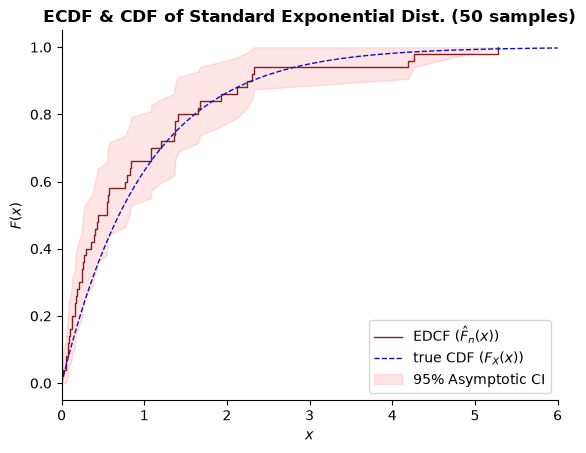

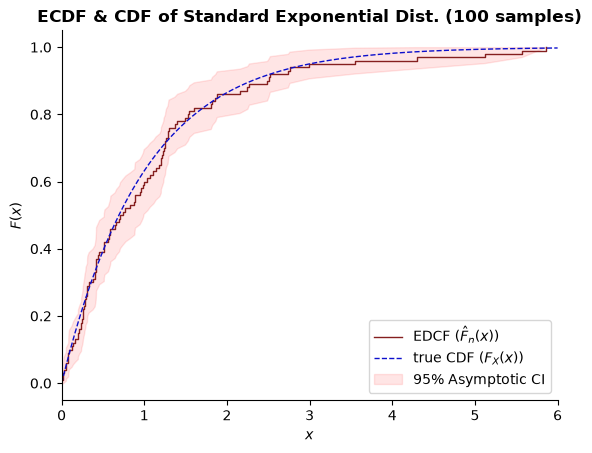

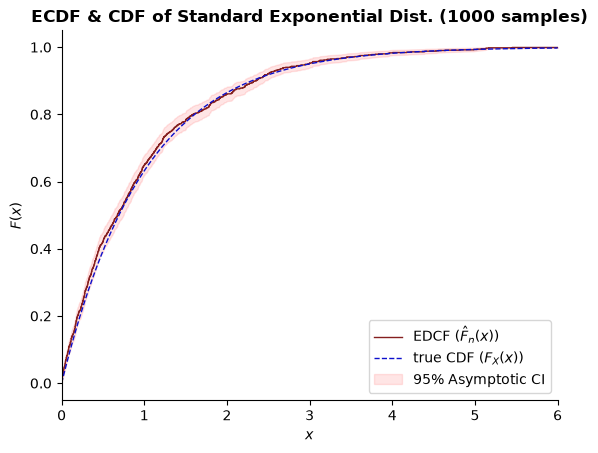

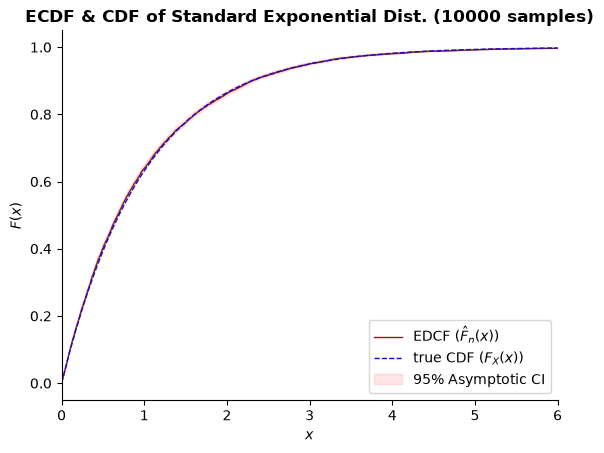

In [31]:
for n in [50, 100, 1000, 10000]:

        # CDF
        x_plot = np.linspace(0, 6, 10000)
        true_cdf = 1 - np.exp(-x_plot)

        # ECDF
        samples  = np.random.exponential(scale=1.0, size = n) # scale = 1/lambda
        sorted_samples = np.sort(samples)
        ecdf = np.arange(1, n+1)/n

        # ECDF_CI
        se = np.sqrt(ecdf*(1-ecdf)/n)
        CI_lower = np.clip(ecdf - 1.96*se, 0,1) #set CI bound to 0-1 using np.clip
        CI_upper = np.clip(ecdf + 1.96*se, 0,1)
    
        fig, ax = plt.subplots()
        ax.step(sorted_samples, 
                ecdf,
                color = "#851F1F", linewidth = 1.0,
                label = r"EDCF ($\hat{F}_n(x)$)",
                where = 'post'
                )

        ax.plot(x_plot, 
                true_cdf,
                linestyle="--", color = "#0C0FCC", linewidth = 1.0, alpha = 1,
                label = "true CDF ($F_X(x)$)"
                )

        ax.fill_between(sorted_samples,
                CI_lower,
                CI_upper,
                color = 'red',
                alpha = 0.1,
                label = '95% Asymptotic CI'
                )

        ax.set_title(f"ECDF & CDF of Standard Exponential Dist. ({n} samples)", fontweight = "bold")
        ax.set_xlabel("$x$")
        ax.set_ylabel("$F(x)$")
        ax.set_xlim(0, 6)
        ax.legend()
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        plt.show()
